# 07 Ridge regression: best features and final submission

Notebook 05 selects λ for least squares / ridge on notebook 01's features and reaches **F1 ≈ 0.412**
(0.420 with undersampling). Here we keep the **same model**, `ridge_regression` from `implementations.py`,
and improve what it is given:

1. **More features**: three groups of raw columns that notebook 01 drops by hand turn out to carry signal.
2. **Non-linear terms**: squares of the numeric columns, and interactions with age and sex.
3. **Class rebalancing** of the training folds, with a tuned undersampling ratio.

Every step is measured with the same stratified 5-fold cross-validation as notebook 05 (F1-tuned threshold
on the out-of-fold scores). The last section retrains the best configuration on all rows and writes
`submission_ridge_best.csv`.

The features are built from the raw CSVs by `feature_engineering.py`, which reproduces notebook 01's cleaning
exactly when no group is added (same 177 columns).

Run time: about 10 minutes (the first run also parses the CSVs once and caches them).

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().resolve().parent
if not (PROJECT_ROOT / "implementations.py").exists():
    PROJECT_ROOT = Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

import feature_engineering as fe
import implementations as impl
from cross_validation import build_k_indices, cross_validation, random_undersample
from helpers import create_csv_submission

# NumPy 2.0 with Apple's Accelerate BLAS emits spurious matmul warnings on finite data.
warnings.filterwarnings("ignore", message=".*encountered in matmul")

K_FOLD = 5
SEED = 1

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2, "font.size": 10,
})

In [2]:
start = time.time()
raw = fe.load_raw(PROJECT_ROOT / "dataset")
decoded = fe.decode_missing(raw)
y = raw["y_train"]
k_indices = build_k_indices(y, K_FOLD, seed=SEED)
print(f"{len(y)} train rows ({y.mean():.2%} positive), {len(raw['test_ids'])} test rows, "
      f"{raw['x_train'].shape[1]} raw columns  ({time.time() - start:.0f}s)")


def features(keep_groups=(), **kwargs):
    # Train and test matrices with the bias column.
    x_tr, x_te, names = fe.build_features(raw, keep_groups=keep_groups, decoded=decoded, **kwargs)
    return np.c_[np.ones(len(x_tr)), x_tr], np.c_[np.ones(len(x_te)), x_te], names


def undersample(ratio):
    # Training-fold rebalancing: all positives + ratio x as many random negatives.
    if ratio is None:
        return None
    return lambda x, y, seed: random_undersample(x, y, seed, ratio=ratio)


def ridge_cv(tx, lambda_, ratio=None):
    return cross_validation(y, tx, "ridge_regression", {"lambda_": lambda_}, k_indices,
                            resample_fn=undersample(ratio), seed=SEED)

328135 train rows (8.83% positive), 109379 test rows, 321 raw columns  (1s)


## 1. Step by step

Each row adds one change to the previous one. `ratio` is the number of negatives kept per positive when
undersampling the training folds (`none` = no rebalancing). The validation folds always keep the real
class distribution.

The three groups are the ones a greedy forward selection kept in notebook 06 (each improved CV F1 by more
than 0.001): `redundant` (13 age bands, income, education, cholesterol, ...), `risk_management`
(blood-pressure medication, diet advice, ...) and `optional_modules`.

In [3]:
GROUPS = ("redundant", "risk_management", "optional_modules")
INTERACT = ("_AGE80", "SEX=2")

steps = [
    ("notebook 01 features", (), {}, 1e-3, None),
    ("+ undersample 1:1", (), {}, 1e-3, 1.0),
    ("+ 3 feature groups", GROUPS, {}, 1e-3, 1.0),
    ("+ squares of numeric columns", GROUPS, {"square_numeric": True}, 1e-3, 1.0),
    ("+ age and sex interactions", GROUPS, {"square_numeric": True, "interact_with": INTERACT}, 1e-3, 1.0),
]

step_results = []
for label, groups, kwargs, lam, ratio in steps:
    start = time.time()
    tx, _, _ = features(groups, **kwargs)
    r = ridge_cv(tx, lam, ratio)
    step_results.append((label, r, tx.shape[1]))
    print(f"{label:<32} D = {tx.shape[1]:>4}   F1 = {r['f1_mean']:.4f} ± {r['f1_std']:.4f}   "
          f"P = {r['precision_mean']:.3f}  R = {r['recall_mean']:.3f}   ({time.time() - start:.0f}s)")
del tx

notebook 01 features             D =  178   F1 = 0.4111 ± 0.0066   P = 0.336  R = 0.531   (1s)
+ undersample 1:1                D =  178   F1 = 0.4213 ± 0.0050   P = 0.354  R = 0.519   (1s)
+ 3 feature groups               D =  816   F1 = 0.4255 ± 0.0044   P = 0.355  R = 0.532   (6s)
+ squares of numeric columns     D =  873   F1 = 0.4258 ± 0.0039   P = 0.352  R = 0.540   (7s)
+ age and sex interactions       D = 1236   F1 = 0.4278 ± 0.0061   P = 0.363  R = 0.521   (10s)


## 2. Tuning λ and the undersampling ratio on the final features

With 1236 columns the best amount of regularization and of rebalancing can change, so we search both on
the final feature set (same folds for every combination).

In [4]:
tx_final, tx_test_final, final_names = features(GROUPS, square_numeric=True, interact_with=INTERACT)
print(f"final features: {tx_final.shape[1]} columns (bias included)")

lambdas = [1e-4, 1e-3, 1e-2]
ratios = [None, 1.0, 1.5, 2.0, 3.0, 5.0]
grid = {}
start = time.time()
for lam in lambdas:
    for ratio in ratios:
        grid[(lam, ratio)] = ridge_cv(tx_final, lam, ratio)
print(f"{len(grid)} combinations x {K_FOLD} folds in {time.time() - start:.0f}s\n")

print(f"{'λ':>7} " + " ".join(f"{('none' if r is None else f'1:{r:g}'):>8}" for r in ratios))
for lam in lambdas:
    print(f"{lam:>7g} " + " ".join(f"{grid[(lam, r)]['f1_mean']:>8.4f}" for r in ratios))

BEST_LAMBDA, BEST_RATIO = max(grid, key=lambda key: grid[key]["f1_mean"])
best_cv = grid[(BEST_LAMBDA, BEST_RATIO)]
print(f"\nbest: λ = {BEST_LAMBDA:g}, ratio = {BEST_RATIO}, "
      f"F1 = {best_cv['f1_mean']:.4f} ± {best_cv['f1_std']:.4f}, threshold = {best_cv['threshold']:.4f}")

final features: 1236 columns (bias included)
18 combinations x 5 folds in 125s

      λ     none      1:1    1:1.5      1:2      1:3      1:5
 0.0001   0.4292   0.4260   0.4294   0.4300   0.4306   0.4314
  0.001   0.4294   0.4278   0.4306   0.4308   0.4316   0.4317
   0.01   0.4285   0.4275   0.4294   0.4299   0.4305   0.4303

best: λ = 0.001, ratio = 5.0, F1 = 0.4317 ± 0.0045, threshold = 0.3586


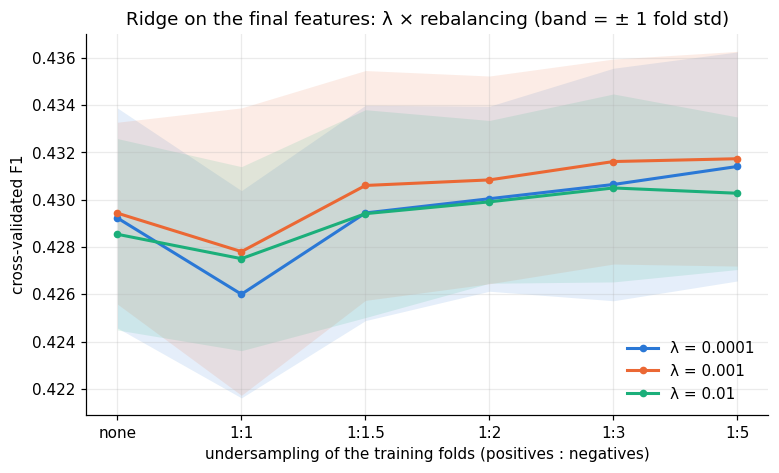

In [5]:
fig, ax = plt.subplots()
x_pos = np.arange(len(ratios))
for lam, color in zip(lambdas, [BLUE, ORANGE, AQUA]):
    means = np.array([grid[(lam, r)]["f1_mean"] for r in ratios])
    stds = np.array([grid[(lam, r)]["f1_std"] for r in ratios])
    ax.fill_between(x_pos, means - stds, means + stds, color=color, alpha=0.12, linewidth=0)
    ax.plot(x_pos, means, color=color, marker="o", markersize=4, label=f"λ = {lam:g}")
ax.set_xticks(x_pos, ["none" if r is None else f"1:{r:g}" for r in ratios])
ax.set_xlabel("undersampling of the training folds (positives : negatives)")
ax.set_ylabel("cross-validated F1")
ax.set_title("Ridge on the final features: λ × rebalancing (band = ± 1 fold std)")
ax.legend(frameon=False)
plt.show()

## 3. Summary

step                                       D              F1 precision recall
notebook 01 features                     178 0.4111 ± 0.0066    0.3356 0.5306
+ undersample 1:1                        178 0.4213 ± 0.0050    0.3545 0.5190
+ 3 feature groups                       816 0.4255 ± 0.0044    0.3546 0.5319
+ squares of numeric columns             873 0.4258 ± 0.0039    0.3516 0.5397
+ age and sex interactions              1236 0.4278 ± 0.0061    0.3629 0.5210
+ tuned λ = 0.001, ratio = 1:5          1236 0.4317 ± 0.0045    0.3587 0.5421


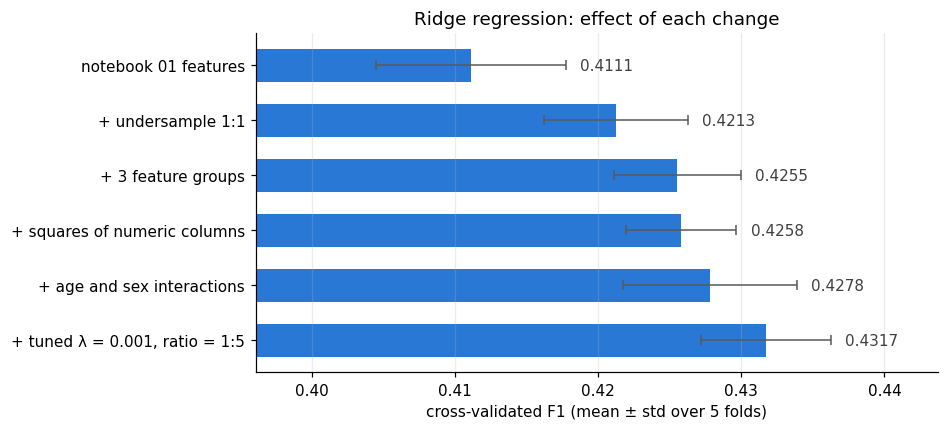

In [6]:
rows = step_results + [(f"+ tuned λ = {BEST_LAMBDA:g}, ratio = {'none' if BEST_RATIO is None else f'1:{BEST_RATIO:g}'}",
                        best_cv, tx_final.shape[1])]

print(f"{'step':<38} {'D':>5} {'F1':>15} {'precision':>9} {'recall':>6}")
for label, r, d in rows:
    print(f"{label:<38} {d:>5} {r['f1_mean']:.4f} ± {r['f1_std']:.4f} {r['precision_mean']:>9.4f} {r['recall_mean']:>6.4f}")

labels = [label for label, _, _ in rows][::-1]
means = np.array([r["f1_mean"] for _, r, _ in rows])[::-1]
stds = np.array([r["f1_std"] for _, r, _ in rows])[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(labels, means, xerr=stds, color=BLUE, height=0.6,
        error_kw={"ecolor": "0.35", "elinewidth": 1, "capsize": 3})
for i, v in enumerate(means):
    ax.text(v + stds[i] + 0.001, i, f"{v:.4f}", va="center", color="0.25")
ax.set_xlim(means.min() - 0.015, means.max() + 0.012)
ax.set_xlabel("cross-validated F1 (mean ± std over 5 folds)")
ax.set_title("Ridge regression: effect of each change")
ax.grid(axis="y", visible=False)
plt.show()

The threshold is tuned on the same out-of-fold scores it is evaluated on, so every number above is slightly
optimistic, by the same small amount for each row. Differences smaller than about one fold std (~0.004)
should not be over-interpreted; the overall gain over notebook 05 is much larger than that.

## 4. Final model and submission

The best configuration is retrained on **all** training rows, with the same undersampling as in
cross-validation, and applied to the test set with the threshold chosen by cross-validation. The predicted
positive rate on the test set should be close to the out-of-fold one.

In [7]:
tx_fit, y_fit = tx_final, y
if BEST_RATIO is not None:
    tx_fit, y_fit = random_undersample(tx_final, y, seed=SEED, ratio=BEST_RATIO)
w_final, _ = impl.ridge_regression(y_fit, tx_fit, BEST_LAMBDA)
print(f"trained on {len(y_fit)} rows ({y_fit.mean():.1%} positive), {tx_final.shape[1]} columns")

threshold = best_cv["threshold"]
test_predictions = np.where(tx_test_final @ w_final >= threshold, 1, -1)
oof_rate = np.mean(best_cv["oof_scores"] >= threshold)
print(f"predicted positive rate: test {np.mean(test_predictions == 1):.4f}, out-of-fold {oof_rate:.4f}")

submission_path = PROJECT_ROOT / "submission_ridge_best.csv"
create_csv_submission(raw["test_ids"], test_predictions, submission_path)
print(f"submission written to {submission_path}")

trained on 173850 rows (16.7% positive), 1236 columns
predicted positive rate: test 0.1339, out-of-fold 0.1335
submission written to /Users/ema/Desktop/EPFL/Machine Learning/ML_Project1/submission_ridge_best.csv


## 5. Conclusions

CONCLUSIONS_PLACEHOLDER